读取点数: 160801
图片已保存到: C:\Users\magic\Desktop\KM-MFSNet\comsol_reference_clouds


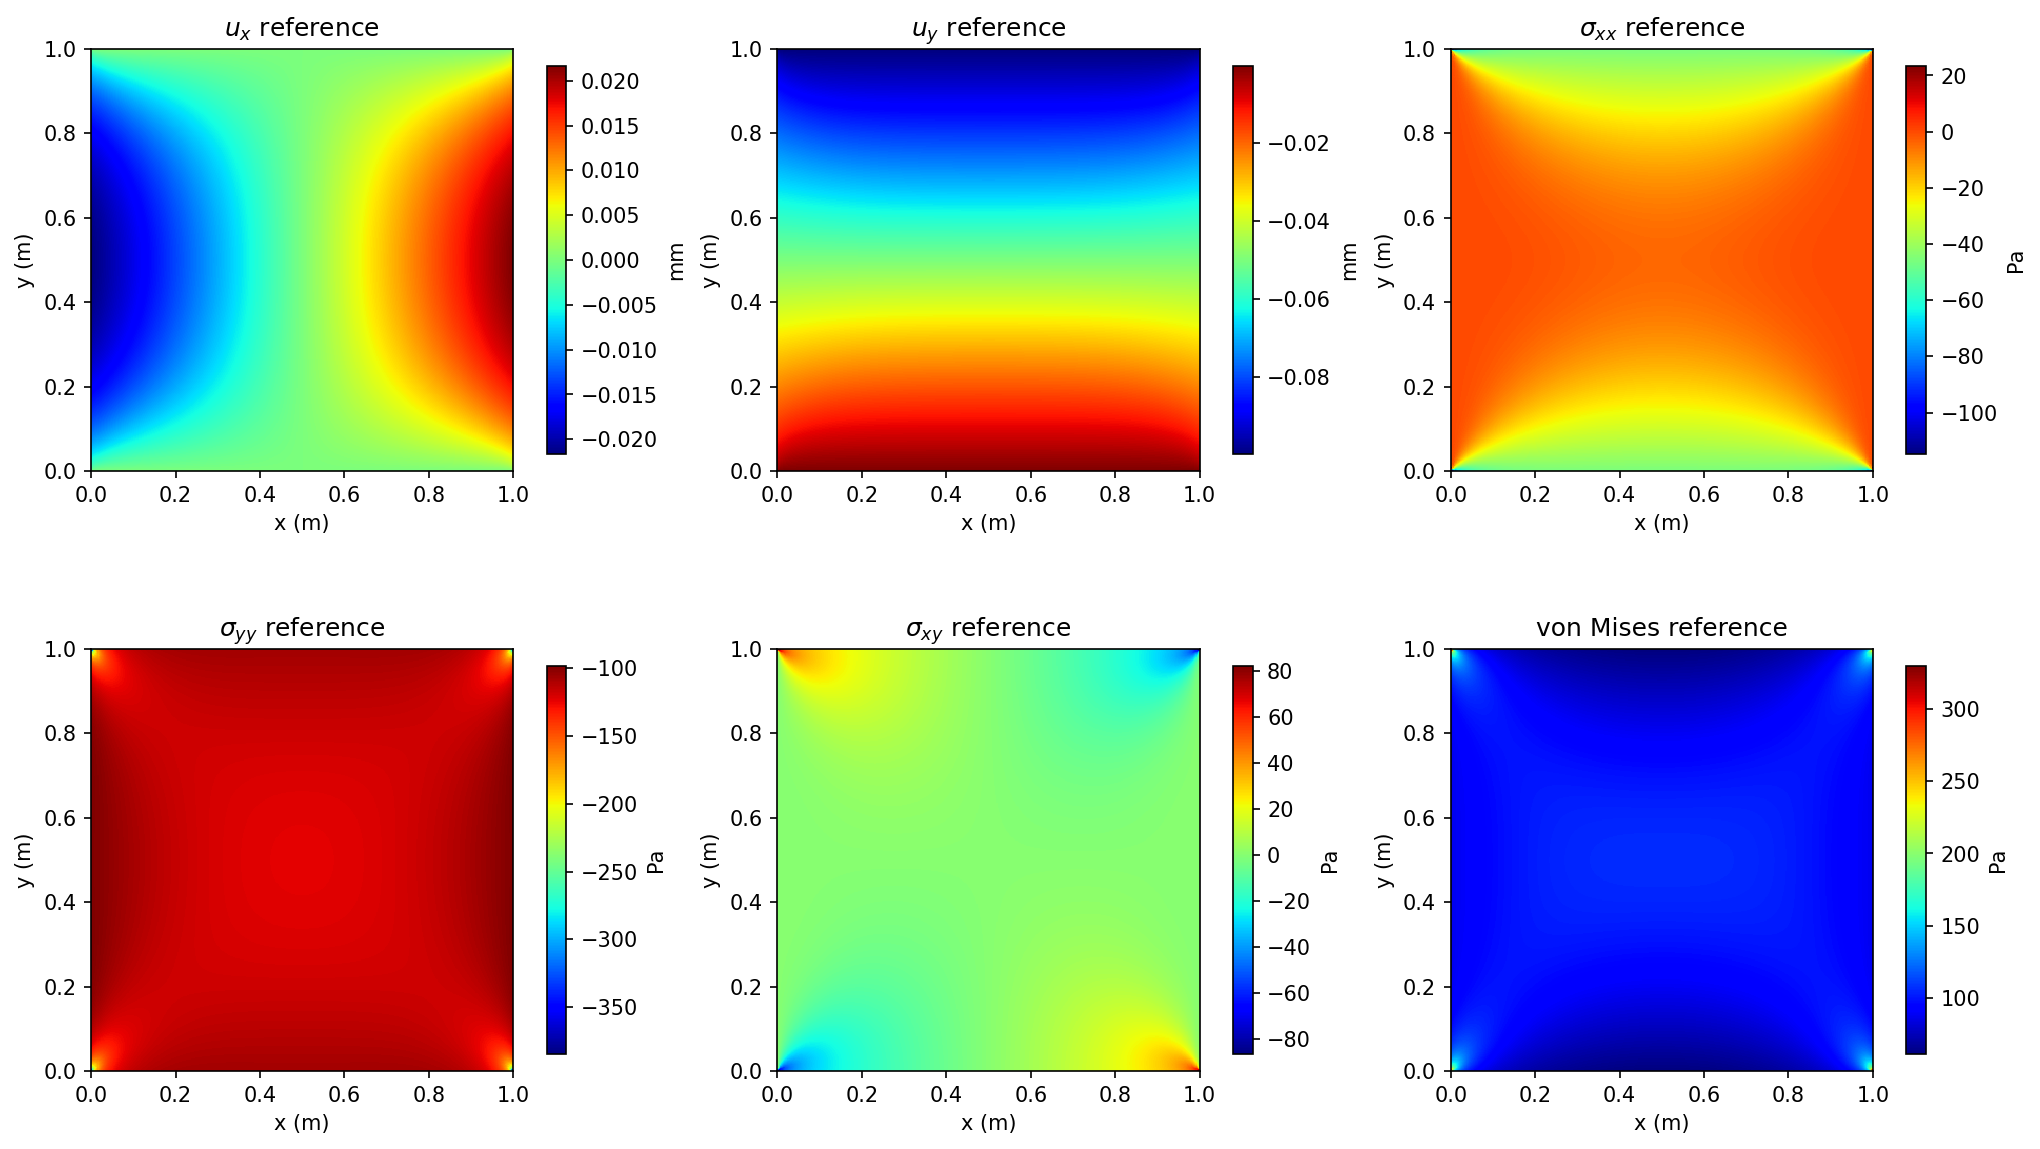

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


# COMSOL 导出的 txt 文件
DATA_PATH = Path(r"C:\Users\magic\Desktop\KM-MFSNet\方板受压comsol.txt")

# 图片输出文件夹
OUT_DIR = Path(r"C:\Users\magic\Desktop\KM-MFSNet\comsol_reference_clouds")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def load_comsol_data(file_path):
    """
    读取 COMSOL 电子表格格式 txt。
    默认列顺序：
    X, Y, u, v, solid.sx, solid.sy, solid.sxy, solid.mises
    """
    data = np.loadtxt(file_path, comments="%")

    x = data[:, 0]
    y = data[:, 1]
    ux = data[:, 2]
    uy = data[:, 3]
    sxx = data[:, 4]
    syy = data[:, 5]
    sxy = data[:, 6]
    mises = data[:, 7]

    return x, y, ux, uy, sxx, syy, sxy, mises


def to_regular_grid(x, y, value):
    """
    将规则栅格点转换成二维矩阵，方便画云图。
    要求 COMSOL 导出时选择：规则栅格 + 电子表格。
    """
    xs = np.unique(np.round(x, 12))
    ys = np.unique(np.round(y, 12))

    nx = len(xs)
    ny = len(ys)

    if nx * ny != len(value):
        raise ValueError("当前数据不是规则网格，请在 COMSOL 中选择：规则栅格 + 电子表格。")

    value_grid = np.zeros((ny, nx))

    ix = np.searchsorted(xs, np.round(x, 12))
    iy = np.searchsorted(ys, np.round(y, 12))

    value_grid[iy, ix] = value

    return xs, ys, value_grid


def plot_cloud(ax, x, y, value, title, unit, cmap="jet"):
    xs, ys, value_grid = to_regular_grid(x, y, value)

    im = ax.pcolormesh(xs, ys, value_grid, shading="auto", cmap=cmap)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(unit)

    return im


def main():
    x, y, ux, uy, sxx, syy, sxy, mises = load_comsol_data(DATA_PATH)

    fields = [
        ("ux", ux * 1e3, r"$u_x$", "mm"),
        ("uy", uy * 1e3, r"$u_y$", "mm"),
        ("sxx", sxx, r"$\sigma_{xx}$", "Pa"),
        ("syy", syy, r"$\sigma_{yy}$", "Pa"),
        ("sxy", sxy, r"$\sigma_{xy}$", "Pa"),
        ("von_mises", mises, "von Mises", "Pa"),
    ]

    # 1. 画一张 2x3 总图
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150, constrained_layout=True)

    for ax, (_, value, title, unit) in zip(axes.ravel(), fields):
        plot_cloud(ax, x, y, value, title + " reference", unit)

    fig.savefig(OUT_DIR / "comsol_reference_6_clouds.png", dpi=300, bbox_inches="tight")

    # 2. 分别保存 6 张单独云图
    for name, value, title, unit in fields:
        fig_single, ax_single = plt.subplots(figsize=(5.2, 4.8), dpi=150, constrained_layout=True)
        plot_cloud(ax_single, x, y, value, title + " reference", unit)
        fig_single.savefig(OUT_DIR / f"comsol_reference_{name}.png", dpi=300, bbox_inches="tight")
        plt.close(fig_single)

    print(f"读取点数: {len(x)}")
    print(f"图片已保存到: {OUT_DIR}")

    plt.show()


if __name__ == "__main__":
    main()